In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import PowerTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [2]:
cols = ['loan_amnt', 'term', 'int_rate', 'grade', 'emp_length', 'home_ownership', 
        'annual_inc', 'purpose', 'dti', 'loan_status','installment','verification_status']

In [3]:
data = pd.read_csv(r'C:\Users\Mayur23\Downloads\accepted_2007_to_2018Q4.csv.gz', usecols = cols)

KeyboardInterrupt: 

In [ ]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2260701 entries, 0 to 2260700
Data columns (total 12 columns):
 #   Column               Dtype  
---  ------               -----  
 0   loan_amnt            float64
 1   term                 str    
 2   int_rate             float64
 3   installment          float64
 4   grade                str    
 5   emp_length           str    
 6   home_ownership       str    
 7   annual_inc           float64
 8   verification_status  str    
 9   loan_status          str    
 10  purpose              str    
 11  dti                  float64
dtypes: float64(5), str(7)
memory usage: 207.0 MB


In [ ]:
data.describe()

,loan_amnt,int_rate,installment,annual_inc,dti
count,2.260668e+06,2.260668e+06,2.260668e+06,2.260664e+06,2.258957e+06
mean,1.504693e+04,1.309283e+01,4.458068e+02,7.799243e+04,1.882420e+01
std,9.190245e+03,4.832138e+00,2.671735e+02,1.126962e+05,1.418333e+01
min,5.000000e+02,5.310000e+00,4.930000e+00,0.000000e+00,-1.000000e+00
25%,8.000000e+03,9.490000e+00,2.516500e+02,4.600000e+04,1.189000e+01
50%,1.290000e+04,1.262000e+01,3.779900e+02,6.500000e+04,1.784000e+01
75%,2.000000e+04,1.599000e+01,5.933200e+02,9.300000e+04,2.449000e+01
max,4.000000e+04,3.099000e+01,1.719830e+03,1.100000e+08,9.990000e+02


In [ ]:
data['term'].unique()

<StringArray>
[' 36 months', ' 60 months', nan]
Length: 3, dtype: str

In [ ]:
map_term = {
    ' 36 months' : 'Short-term',
    ' 60 months' : 'Long-term'
}
data['term_class'] = data['term'].map(map_term).fillna('Unknown')
data = data.drop('term',axis = 1)

In [ ]:
data['emp_length'].unique()

<StringArray>
['10+ years',   '3 years',   '4 years',   '6 years',    '1 year',   '7 years',
   '8 years',   '5 years',   '2 years',   '9 years',  '< 1 year',         nan]
Length: 12, dtype: str

In [ ]:
map_emp_length = {
    '< 1 year' : 'Junior',
    '1 year' : 'Junior',
    '2 years' : 'Junior',
    '3 years' : 'Intermediate',
    '4 years' : 'Intermediate',
    '5 years' : 'Intermediate',
    '6 years' : 'Experienced',
    '7 years' : 'Experienced',
    '8 years' : 'Experienced',
    '9 years' : 'Experienced',
    '10 years' : 'Veteran',
    '10+ years' : 'Veteran',
}

data['emp_class'] = data['emp_length'].map(map_emp_length)
data = data.drop('emp_length',axis = 1)

In [ ]:
default_map = {
    'Fully Paid': 'Paid',
    'Does not meet the credit policy. Status:Fully Paid': 'Paid',
    'Charged Off': 'Not Paid',
    'Default': 'Not Paid',
    'Does not meet the credit policy. Status:Charged Off': 'Not Paid'
}

data['default'] = data['loan_status'].map(default_map)
data = data.dropna(subset=['default'])

In [ ]:
data = data.drop('loan_status',axis = 1)

In [ ]:
data.sample(5)

,loan_amnt,int_rate,installment,grade,home_ownership,annual_inc,verification_status,purpose,dti,term_class,emp_class,default
1155605,24000.0,8.39,756.40,A,RENT,70000.0,Source Verified,credit_card,23.59,Short-term,Junior,Paid
1612414,16000.0,9.91,515.60,B,RENT,50000.0,Not Verified,debt_consolidation,15.10,Short-term,Veteran,Paid
1236989,16000.0,16.29,391.56,D,RENT,120000.0,Source Verified,debt_consolidation,19.71,Long-term,Experienced,Not Paid
915414,2500.0,15.05,86.73,C,MORTGAGE,45000.0,Source Verified,home_improvement,27.09,Short-term,Intermediate,Paid
325078,20000.0,16.99,712.96,D,MORTGAGE,74000.0,Source Verified,debt_consolidation,24.73,Short-term,Intermediate,Not Paid


In [ ]:
print("Output class:",data['default'].value_counts())

Output class: default
Paid        1078739
Not Paid     269360
Name: count, dtype: int64


In [ ]:
data_cleaned = data.copy()

In [ ]:
data.isnull().sum()

loan_amnt                  0
int_rate                   0
installment                0
grade                      0
home_ownership             0
annual_inc                 4
verification_status        0
purpose                    0
dti                      374
term_class                 0
emp_class              78550
default                    0
dtype: int64

In [ ]:
data['home_ownership'].unique()

<StringArray>
['MORTGAGE', 'RENT', 'OWN', 'ANY', 'NONE', 'OTHER']
Length: 6, dtype: str

In [ ]:
data['verification_status'].unique()

<StringArray>
['Not Verified', 'Source Verified', 'Verified']
Length: 3, dtype: str

In [ ]:
data['purpose'].unique()

<StringArray>
['debt_consolidation',     'small_business',   'home_improvement',
     'major_purchase',        'credit_card',              'other',
              'house',           'vacation',                'car',
            'medical',             'moving',   'renewable_energy',
            'wedding',        'educational']
Length: 14, dtype: str

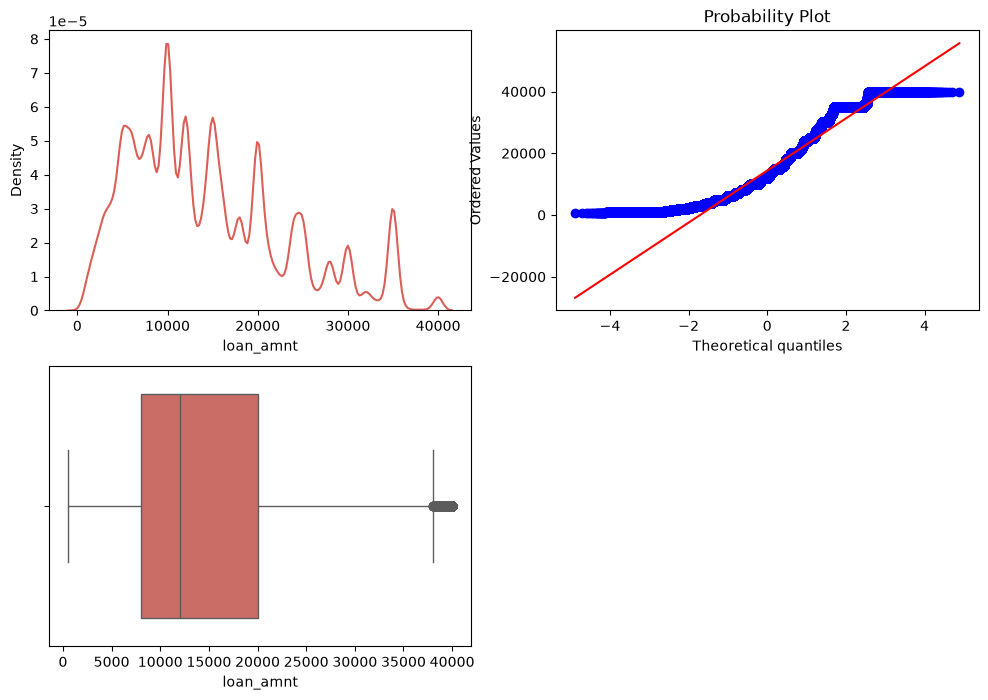

In [ ]:
sns.set_palette('hls',8)
plt.figure(figsize = (12,8))
plt.subplot(2,2,1)
sns.kdeplot(data = data['loan_amnt'])

plt.subplot(2,2,2)
stats.probplot(data['loan_amnt'],dist='norm',plot = plt )

plt.subplot(2,2,3)
sns.boxplot(data = data,x=data['loan_amnt'])
plt.show()

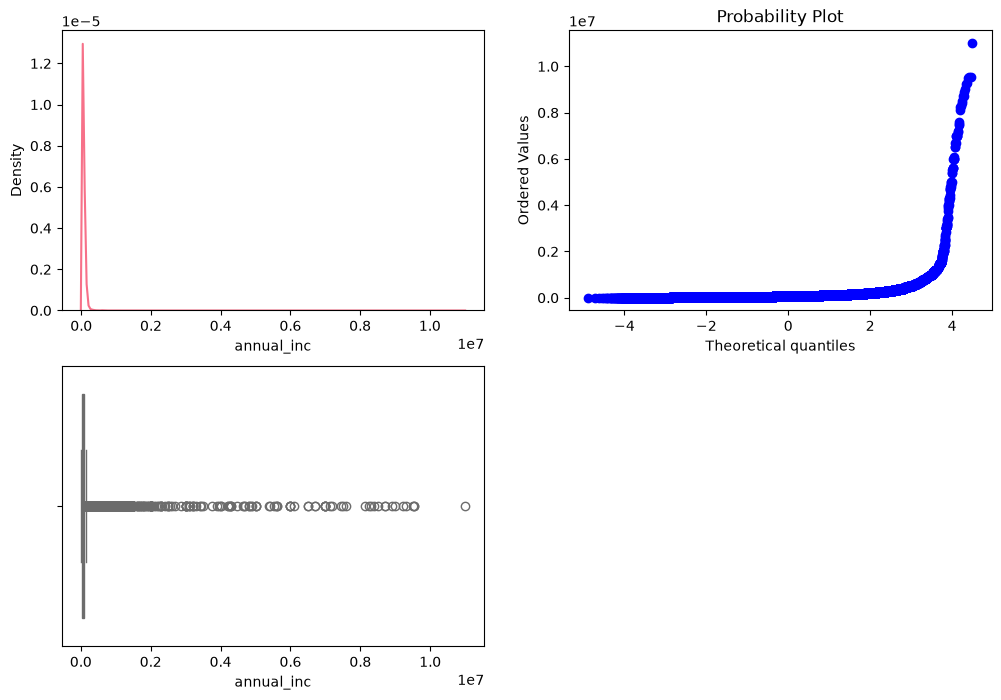

In [ ]:
sns.set_palette('husl',8)
plt.figure(figsize = (12,8))
plt.subplot(2,2,1)
sns.kdeplot(data = data['annual_inc'])

plt.subplot(2,2,2)
stats.probplot(data['annual_inc'],dist='norm',plot = plt )

plt.subplot(2,2,3)
sns.boxplot(data = data,x=data['annual_inc'])
plt.show()

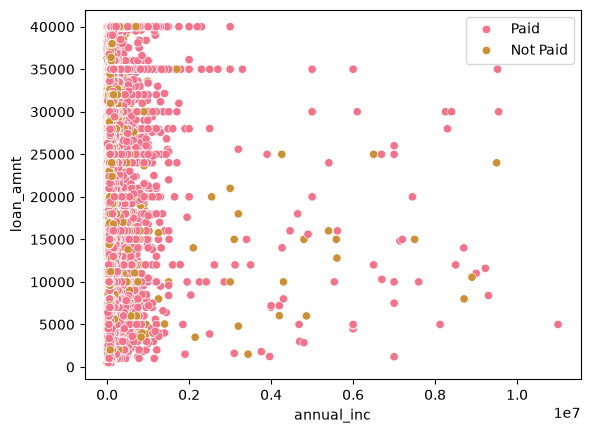

In [ ]:
sns.scatterplot(data = data,x=data['annual_inc'],y=data['loan_amnt'],hue=data['default'])
plt.legend(loc='upper right')
plt.show()

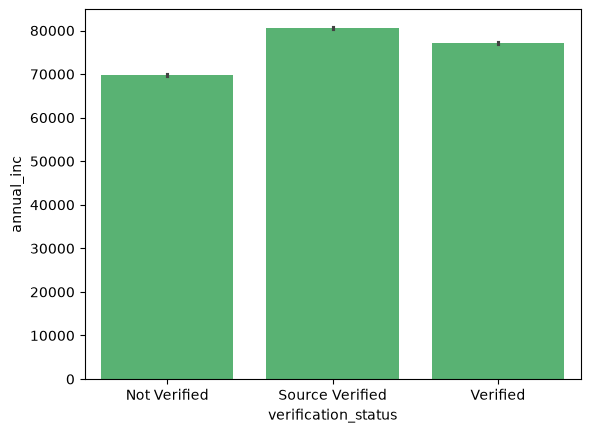

In [ ]:
sns.barplot(data=data,x=data['verification_status'],y=data['annual_inc'],color = sns.color_palette('viridis')[4])
plt.show()

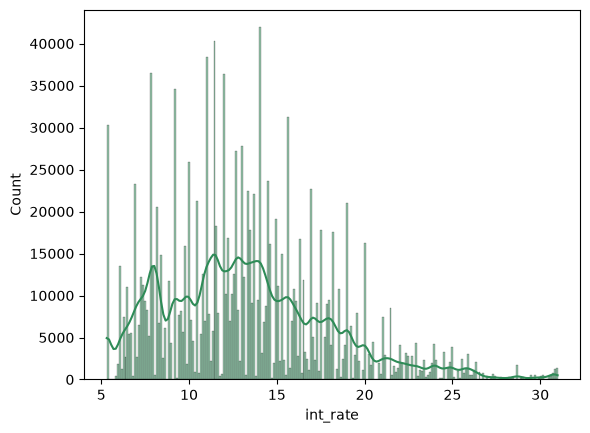

In [ ]:
sns.histplot(x=data['int_rate'],kde='true',color = sns.light_palette("seagreen")[5])
plt.show()

<Axes: xlabel='dti', ylabel='Count'>

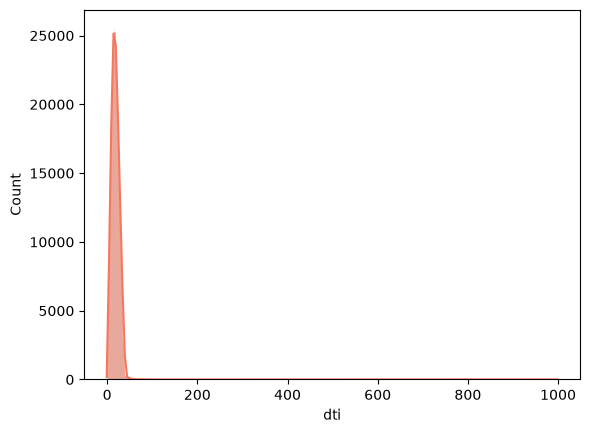

In [ ]:
sns.histplot(x=data['dti'],kde='true',color = sns.color_palette("magma")[4])

In [ ]:
print(data.isna().sum())

loan_amnt                  0
int_rate                   0
installment                0
grade                      0
home_ownership             0
annual_inc                 4
verification_status        0
purpose                    0
dti                      374
term_class                 0
emp_class              78550
default                    0
dtype: int64
